# Why the formulation ranking changes

**A-T has a measured coefficient-accuracy advantage for the deeper stages and positive shifts tested here. A-phi wins the original order-1, zero-shift, first-three-element comparison.** The two statements describe different tests.

This notebook identifies the public baseline plot, compares the same physical round wire on caller-owned shared 3D meshes, and varies the metric window, FE order and real shift explicitly. The evidence contains 40 field-recursion cases (one deliberately retained quadrature/load rejection) and 36 independent pencil/ladder cases.

The conductor radius and length are 10 mm, sigma=1e6 S/m, mu=mu0. The magnetic boundary is n x A=0 over the conductor surface: internal energy only, with no exterior return-path model. The axial electric drive is 1 V/m. Baseline coefficient normalization is per metre divided by cylinder length; terminal R and L multiply length squared. All comparisons use the corresponding analytic Bessel oracle.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'validation').is_dir(): root=root.parent
baseline=json.loads((root/'docs/data/three_dimensional.json').read_text(encoding='utf8'))
study=json.loads((root/'docs/data/formulation_ranking.json').read_text(encoding='utf8'))
shifted=json.loads((root/'docs/data/shifted_formulation_ranking.json').read_text(encoding='utf8'))
print('Native runtime:', study['runtime'])
print('Matched meshes:', [(v['maxh'],v['ne'],v['mesh_sha256'][:12]) for v in study['meshes']])
print('Complete:',study['complete'],shifted['complete'])
print('Max original residual, field recursion:',max(c.get('max_original_residual',0) for c in study['cases']))
print('Max original residual, independent pencils:',max(v['true_residual'] for c in shifted['cases'] for v in c['solve_diagnostics']))


Native runtime: {'host': 'intel11', 'python': '3.12.10', 'ngsolve': '6.2.2607', 'radia': '5.2.3', 'numpy': '2.5.2', 'mpmath': '1.3.0'}
Matched meshes: [(0.003, 510, '536a10934ff9'), (0.002, 1510, 'a27aa19d3e8c'), (0.0015, 5140, '7cf7a4603d40')]
Complete: True True
Max original residual, field recursion: 5.28531480848224e-09
Max original residual, independent pencils: 1.4009163892147658e-13


## Identify the original plot from its source

The two-panel figure in [notebook 06](06_3d_round_wire.ipynb) plots `max(relative_errors)` of **R0, L1 and R2**, against mesh size, and the axial E2 profile on the right. Its producer is `validation/validate_3d.py`, with **order=1, s0=0**, curved geometry order 3 and extra quadrature 4. It is not a positive-shift, five-element test. The stored numbers reproduce the visible ranking.

The spaces also differ despite the common label p: A-phi uses full HCurl(A,p) and H1(phi,p+1); T-Omega uses compact HCurl(T,p) and H1(Omega,p+1); A-T uses compact HCurl(A,p) and HCurl(T,p). Equal nominal p and equal mesh do not mean equal field spaces or degrees of freedom.

Original plot: max error over R0/L1/R2 [%]
A-phi     h= 3.0 mm  4.800371%
A-phi     h= 1.0 mm  0.667072%
T-Omega   h= 3.0 mm  18.241621%
T-Omega   h= 1.0 mm  2.107524%
A-T       h= 3.0 mm  12.976375%
A-T       h= 1.0 mm  1.430462%
New matched comparison: common mesh, quadrature 8, three stages
p   h[mm]  formulation   first3[%]   first5[%]   first7[%]
1    3.0   CLN_APhi         4.800382   45.640355   80.559579
1    3.0   CLN_T_Omega     18.241647  165.557528  626.378878
1    3.0   CLN_AT          12.976387   52.788220   61.931811
2    3.0   CLN_APhi         0.014713    4.196210   32.944478
2    3.0   CLN_T_Omega      0.134670    6.914948   65.414707
2    3.0   CLN_AT           0.120890    2.434889   11.937289
3    3.0   CLN_APhi         0.000658    0.049918    3.165748
3    3.0   CLN_T_Omega      0.000645    0.091124    4.189945
3    3.0   CLN_AT           0.000645    0.042249    0.907121
1    2.0   CLN_APhi         2.453386   27.448135   65.426808
1    2.0   CLN_T_Omega      8.699077

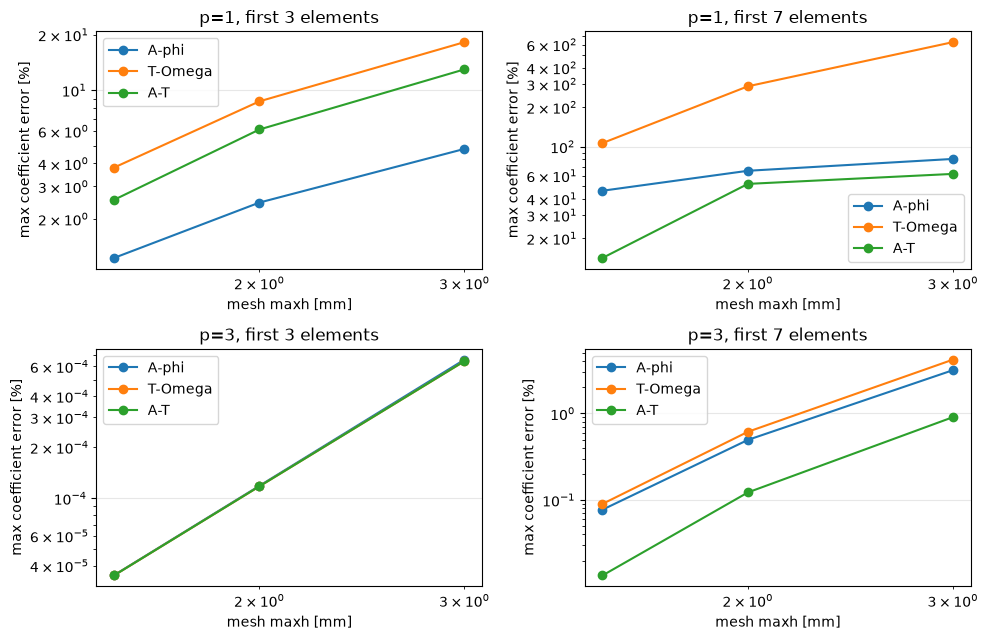

In [2]:
print('Original plot: max error over R0/L1/R2 [%]')
for c in baseline['cases']:
    print(f"{c['formulation']:9} h={1e3*c['maxh']:4.1f} mm  {100*max(c['relative_errors']):.6f}%")
rows=[c for c in study['cases'] if c['control']=='baseline']
names=['CLN_APhi','CLN_T_Omega','CLN_AT']
labels=['A-phi','T-Omega','A-T']
print('New matched comparison: common mesh, quadrature 8, three stages')
print('p   h[mm]  formulation   first3[%]   first5[%]   first7[%]')
for c in rows:
    e=c['max_absolute_relative_error']
    print(f"{c['order']}   {1e3*c['maxh']:4.1f}   {c['formulation']:13} " + ' '.join(f'{100*e[str(n)]:11.6f}' for n in (3,5,7)))
fig,axes=plt.subplots(2,2,figsize=(10,6.5))
for row,p in enumerate((1,3)):
    for col,count in enumerate((3,7)):
        ax=axes[row,col]
        for name,label in zip(names,labels):
            subset=[c for c in rows if c['order']==p and c['formulation']==name]
            ax.loglog([1e3*c['maxh'] for c in subset],[100*c['max_absolute_relative_error'][str(count)] for c in subset],'o-',label=label)
        ax.set(title=f'p={p}, first {count} elements',xlabel='mesh maxh [mm]',ylabel='max coefficient error [%]')
        ax.grid(alpha=.3);ax.legend()
plt.tight_layout();plt.show()


The ranking reverses **without changing mesh, shift or FE order** when the coefficient window changes. On the p=1, 3 mm mesh, A-phi has 4.80% first-three error versus A-T's 12.98%; for seven elements, A-T has 61.93% versus A-phi's 80.56%. These coarse deep-element errors are large: winning a ranking is not passing an accuracy requirement.

At p=3 and 1.5 mm, seven-element errors are approximately 0.0773% (A-phi), 0.0901% (T-Omega) and 0.0134% (A-T). The matched study uses the same shared mesh object for every formulation, matching materials, drive, geometry order, quadrature and residual gate. The JSON retains mesh fingerprints, actual DOFs, signed element errors and solve diagnostics.

## Isolate the approximation-space effect

Two controls on the same coarse mesh enrich only one A-T vector space. `enrich_A` raises the A order by one and keeps T fixed; `enrich_T` does the converse. This is a mechanism check, not an equal-DOF efficiency comparison.

Signed coefficient errors [%], p=1, h=3 mm:
CLN_APhi baseline [-6.400000e-04 -2.003260e+00 -4.800380e+00 -3.400336e+01 -4.564035e+01
 -7.731262e+01 -8.055958e+01]
CLN_T_Omega baseline [2.4660000e-02 2.7213000e-01 1.8241650e+01 3.4010990e+01 1.6555753e+02
 1.9813884e+02 6.2637888e+02]
CLN_AT baseline [ 2.466000e-02 -1.726740e+00  1.297639e+01 -7.607220e+00  5.278822e+01
 -2.116360e+01  6.193181e+01]
CLN_AT enrich_A [2.4660000e-02 2.7024000e-01 1.8226390e+01 3.3792630e+01 1.6457836e+02
 1.7626747e+02 4.3554452e+02]
CLN_AT enrich_T [ 6.000000e-05 -2.002260e+00 -4.742860e+00 -3.372682e+01 -4.370355e+01
 -7.256572e+01 -6.893533e+01]


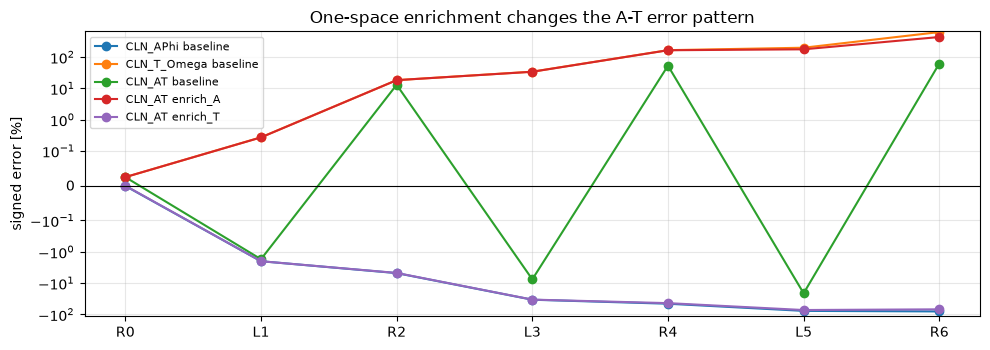

In [3]:
selected=[c for c in study['cases'] if c['maxh']==.003 and c['order']==1 and c['stages']==3 and c['control'] in ('baseline','enrich_A','enrich_T')]
print('Signed coefficient errors [%], p=1, h=3 mm:')
for c in selected:
    print(c['formulation'],c['control'],np.round(100*np.asarray(c['signed_relative_errors']),5))
fig,ax=plt.subplots(figsize=(10,3.6))
for c in selected:
    ax.plot(range(7),100*np.asarray(c['signed_relative_errors']),'o-',label=c['formulation']+' '+c['control'])
ax.axhline(0,color='k',lw=.8)
ax.set_yscale('symlog',linthresh=.1)
ax.set(xticks=range(7),xticklabels=['R0','L1','R2','L3','R4','L5','R6'],ylabel='signed error [%]',title='One-space enrichment changes the A-T error pattern')
ax.grid(alpha=.3);ax.legend(fontsize=8);plt.tight_layout();plt.show()


On these controls, enriching A moves the R2 error toward T-Omega; enriching T moves it toward A-phi. The p=1 A-phi coefficients are below the oracle, T-Omega coefficients are above it, while A-T alternates their error signs. The controls support an interplay between electric and magnetic discretization errors; they do not prove universal cancellation or a continuum theorem.

The initial field and scalar reconstruction also matter. A-phi represents the uniform E0 particularly accurately on this wire; the curl(T) routes have a larger E0 error. A-T still has a measured deeper-element advantage. A coefficient ranking therefore cannot be substituted for a field ranking.

## Check a positive real expansion point independently

`wire_pencils.py` assembles the full finite-element linear-response operators on the same 3D meshes. It applies scalar and magnetic Schur complements, with NGSolve sparsecholesky subsolves and checked matrix-free CG. Gauge terms act on checked gradient kernels; no artificial physical mass or PARDISO solve is used. Taylor response moments generate five-element continued fractions; this is an **independent response oracle**, not a second field-recursion implementation.

At zero shift its first-five coefficients match the field recursions within 2e-6 relative, including the numerical sensitivity of A-phi moment extraction. Independent Taylor Pade checks verify continued-fraction evaluation. Positive shift is s0=2*pi*1e5, or z0=tau*s0=8*pi^2; it is a real Laplace shift, not an AC interpolation frequency. Both Type1 and Type2 are checked against their own analytic coefficients.

Positive real shift: maximum first-five coefficient error [%]
p  h[mm]  formulation  type     error[%]
1   3.0   A-Phi      Type2  91.605048
1   3.0   A-Phi      Type1  91.961152
1   3.0   T-Omega    Type2  1011.692963
1   3.0   T-Omega    Type1  861.191210
1   3.0   A-T        Type2  16.745548
1   3.0   A-T        Type1  16.968289
2   3.0   A-Phi      Type2  58.854763
2   3.0   A-Phi      Type1  58.809335
2   3.0   T-Omega    Type2  161.425547
2   3.0   T-Omega    Type1  140.273049
2   3.0   A-T        Type2  14.696571
2   3.0   A-T        Type1  14.042348
3   3.0   A-Phi      Type2  17.516291
3   3.0   A-Phi      Type1  16.665326
3   3.0   T-Omega    Type2  24.597158
3   3.0   T-Omega    Type1  21.689314
3   3.0   A-T        Type2  3.406334
3   3.0   A-T        Type1  3.129321
3   1.5   A-Phi      Type2  1.153223
3   1.5   A-Phi      Type1  1.043318
3   1.5   T-Omega    Type2  1.231460
3   1.5   T-Omega    Type1  1.108157
3   1.5   A-T        Type2  0.089088
3   1.5   A-T        Type

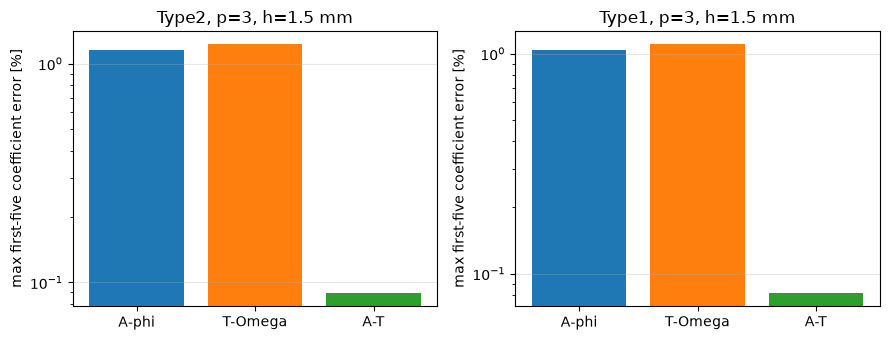

In [4]:
print('Positive real shift: maximum first-five coefficient error [%]')
print('p  h[mm]  formulation  type     error[%]')
for c in shifted['cases']:
    if c['z0']>0:
        print(f"{c['order']}  {1e3*c['maxh']:4.1f}   {c['formulation']:9}  {c['type']:5}  {100*c['max_first5_error']:.6f}")
fine=[c for c in shifted['cases'] if c['maxh']==.0015 and c['order']==3 and c['z0']>0]
for kind in ('Type1','Type2'):
    group={c['formulation']:c['max_first5_error'] for c in fine if c['type']==kind}
    print(kind,'A-phi/A-T error ratio:',group['A-Phi']/group['A-T'],'T-Omega/A-T:',group['T-Omega']/group['A-T'])
fig,axes=plt.subplots(1,2,figsize=(9,3.5))
for ax,kind in zip(axes,('Type2','Type1')):
    group={c['formulation']:c['max_first5_error'] for c in fine if c['type']==kind}
    ax.bar(labels,[100*group[name] for name in ['A-Phi','T-Omega','A-T']],color=['C0','C1','C2'])
    ax.set(yscale='log',ylabel='max first-five coefficient error [%]',title=f'{kind}, p=3, h=1.5 mm')
    ax.grid(axis='y',alpha=.3)
plt.tight_layout();plt.show()


For the matched p=3, 1.5 mm Type2 case, A-phi has 1.1532% error, T-Omega 1.2315%, and A-T 0.08909%: A-T is approximately **13 times better** on this coefficient metric. Type1 gives a similar ratio. This independently reproduces a substantial A-T advantage with stricter original-system residuals, rather than treating an earlier approximate factor of fifteen as a universal constant.

Shift alone can reverse the first-three ranking: on the unchanged p=1, 3 mm mesh, zero-shift Type2 favors A-phi (4.80% versus A-T 12.98%), but positive-shift Type2 favors A-T (15.69% versus A-phi 63.83%). The latter coarse errors still fail a 1% accuracy target.

## Does better element accuracy imply better terminal impedance?

No. These plots evaluate the finite zero-shift ladders on s=j*omega and compare with the Bessel impedance. They show **total FE plus truncation error**, not reduction error against each route's own direct FE response. The ideal analytic seven-element ladder is plotted separately so that truncation remains visible. The display floor is 1e-14 to avoid interpreting floating-point noise as accuracy; the JSON retains the raw errors.

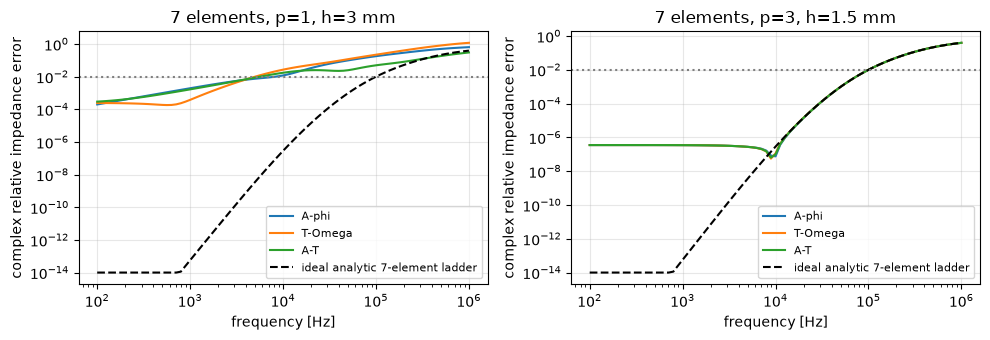

Raw native elapsed times are in JSON; they are single runs, not a performance ranking.
Retained diagnostic rejections:
CLN_T_Omega quadrature4 Incompatible load [T stage 3]: kernel fraction 1.224e-08 exceeds 1.000e-08


In [5]:
freq=np.asarray(study['frequency_hz'])
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
for ax,p,h in [(axes[0],1,.003),(axes[1],3,.0015)]:
    for name,label in zip(names,labels):
        c=next(c for c in rows if c['formulation']==name and c['order']==p and c['maxh']==h)
        ax.loglog(freq,np.maximum(c['terminal_total_relative_error']['7'],1e-14),label=label)
    ax.loglog(freq,np.maximum(study['analytic_truncation_relative_error']['7'],1e-14),'k--',label='ideal analytic 7-element ladder')
    ax.axhline(.01,color='grey',ls=':')
    ax.set(xlabel='frequency [Hz]',ylabel='complex relative impedance error',title=f'7 elements, p={p}, h={1e3*h:g} mm')
    ax.grid(alpha=.3);ax.legend(fontsize=8)
plt.tight_layout();plt.show()
print('Raw native elapsed times are in JSON; they are single runs, not a performance ranking.')
print('Retained diagnostic rejections:')
for c in study['cases']:
    if c['status']!='pass':print(c['formulation'],c['control'],c['error'])


At high p the finite-ladder truncation error largely hides the coefficient-accuracy advantage; the three terminal curves approach the same ideal finite ladder. At coarser settings, smaller total error can also involve cancellation of discretization and truncation errors. Neither observation establishes a generally better formulation.

## Reproduce and review

- `python validation/formulation_ranking.py --output docs/data/formulation_ranking.json` (NGSolve, Radia, scipy, numpy, mpmath; four threads).
- `python validation/shifted_formulation_ranking.py --output docs/data/shifted_formulation_ranking.json` (same native dependencies).
- `python validation/validate_formulation_ranking.py` (portable saved-evidence checks; numpy and mpmath).

The field study retains the known coarse p=1, quadrature-4 T-Omega load rejection as a failed diagnostic; no tolerance is relaxed. Its matched quadrature-8 baseline completes all 27 cases. The validator checks source hashes, coverage, shared mesh identities, coefficients, signed errors, window maxima, field profiles, terminal curves, zero-shift field/pencil agreement, shifts and enrichment controls. Five deliberate corruptions are rejected.

The numerical evidence was produced on the recorded LAB runtime. No cost superiority, universal field advantage, general 3D geometry result, complex-shift result, all-order convergence or passivity in physical s is claimed. These independent checks are self-review; a new external scientific review is not claimed. See [review status](REVIEW_STATUS.md) and [accuracy definitions](ACCURACY_REVIEW.md).

High-order local vector-potential recovery is investigated separately in [notebook 18](18_element_curl_recovery.ipynb). Its local recovery result does not imply that the full CLN problem is element-local.